# 00 · Results overview

All experiments at a glance. This notebook only **reads** the run folders (`runs/*/config.json` and
`metrics.json`), so it updates itself: re-run it after every new experiment.

| Folder | Notebooks |
|---|---|
| `notebooks/data/` | 01 EDA · 02 data quality · 03 split · 04 haze correction · 05 Fourier analysis |
| `notebooks/experiments/` | E01 baseline · E02 hist_split · E03 AdaBN · E04 contrast aug · E05–E07 Fourier A/B/C |

**The task in one sentence:** the training images (EuroSAT, Level-1C) contain haze, the Kaggle test
images (Level-2A) are atmospherically corrected, so a model that reaches 99% on EuroSAT scores far
lower on Kaggle. Every experiment tries to close that gap.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import PROJECT_ROOT
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style

apply_style()

rows = []
for run in sorted((PROJECT_ROOT / "runs").iterdir()):
    if not (run / "metrics.json").exists():
        continue
    config = json.loads((run / "config.json").read_text())
    metrics = json.loads((run / "metrics.json").read_text())
    rows.append({
        "notebook": config.get("notebook", "?"),
        "description": config.get("description", run.name),
        "internal test (%)": (metrics.get("internal_test_acc") or np.nan) * 100,
        "Kaggle public (%)": (metrics.get("kaggle_public_score") or np.nan) * 100,
        "parameters": config.get("n_params"),
        "base_run": Path(config["base_run"]).name if "base_run" in config else None,
        "run": run.name,
    })
runs = pd.DataFrame(rows)
# Order: by experiment notebook, a base model before its AdaBN version
runs = runs.assign(_adabn=runs["base_run"].notna()).sort_values(["notebook", "_adabn", "run"]) \
           .drop(columns="_adabn").reset_index(drop=True)
print(f"{len(runs)} runs, {runs['Kaggle public (%)'].notna().sum()} submitted to Kaggle")

12 runs, 8 submitted to Kaggle


## 1 · All runs

In [2]:
table = runs.drop(columns=["run", "base_run"]).copy()
table["internal test (%)"] = table["internal test (%)"].round(2)
table["Kaggle public (%)"] = table["Kaggle public (%)"].round(2)
best = runs["Kaggle public (%)"].idxmax()
print(f"Best Kaggle public score: {runs.loc[best, 'Kaggle public (%)']:.2f}%  ({runs.loc[best, 'run']})")
table.style.format(precision=2, na_rep="–").hide(axis="index")

Best Kaggle public score: 68.18%  (2026-10-12_1040_adabn_balanced_contrast_aug_hist_split_effb0)


notebook,description,internal test (%),Kaggle public (%),parameters
E01_baseline,"EfficientNet-B0, 12 bands, no correction",98.79,56.48,4022950
E02_hist_split,+ histogram matching of training images (hist_split),98.64,64.06,4022950
E03_adabn,E02 + AdaBN on all Kaggle images,–,–,4022950
E03_adabn,E02 + AdaBN balanced (water share matched),–,65.28,4022950
E04_contrast_aug,hist_split + contrast/brightness augmentation,98.77,64.39,4022950
E04_contrast_aug,hist_split + contrast/brightness augmentation + AdaBN balanced,–,68.18,4022950
E05_fourier_A_fda,E04 + Fourier A: FDA augmentation,98.79,–,4022950
E05_fourier_A_fda,E04 + Fourier A: FDA augmentation + AdaBN balanced,–,66.26,4022950
E06_fourier_B_spectral,E04 + Fourier B: spectral matching of training images,98.57,–,4022950
E06_fourier_B_spectral,E04 + Fourier B: spectral matching + AdaBN balanced,–,67.85,4022950


## 2 · Kaggle score per experiment

Submitted runs by experiment (a base model before its AdaBN version). The dashed line is the baseline. The public
leaderboard uses about half of the test images, so differences below about 1 point are within noise.

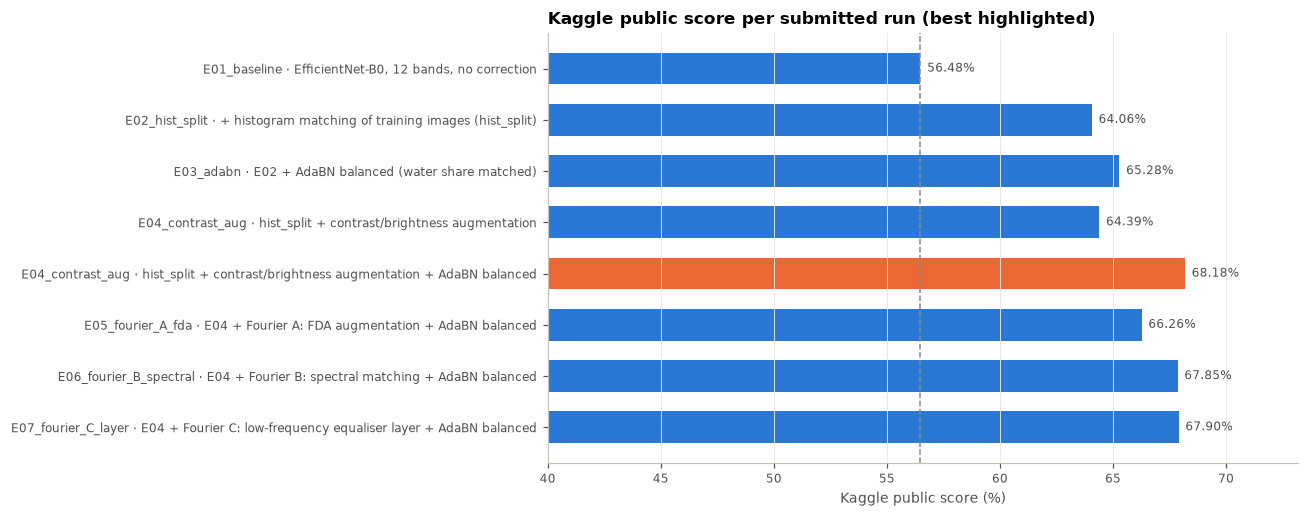

In [3]:
sub = runs.dropna(subset=["Kaggle public (%)"]).reset_index(drop=True)
labels = [f"{n} · {d}" for n, d in zip(sub["notebook"], sub["description"])]
y = np.arange(len(sub))[::-1]
colors = [TEST_COLOR if i == sub["Kaggle public (%)"].idxmax() else TRAIN_COLOR for i in range(len(sub))]

fig, ax = plt.subplots(figsize=(12, 0.45 * len(sub) + 1.2))
ax.barh(y, sub["Kaggle public (%)"], color=colors, height=0.62)
for yi, v in zip(y, sub["Kaggle public (%)"]):
    ax.text(v + 0.3, yi, f"{v:.2f}%", va="center", fontsize=8, color="#52514e")
baseline = sub.loc[sub["notebook"] == "E01_baseline", "Kaggle public (%)"].iloc[0]
ax.axvline(baseline, color=MUTED, ls="--", lw=1)
ax.set_yticks(y, labels, fontsize=8)
ax.set_xlim(40, max(sub["Kaggle public (%)"]) + 5)
ax.set_xlabel("Kaggle public score (%)")
ax.set_title("Kaggle public score per submitted run (best highlighted)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3 · The domain gap

For every submitted model: accuracy on the internal EuroSAT test split vs the Kaggle score. The models
learn EuroSAT almost perfectly; everything between the two dots is lost to the Level-1C → Level-2A shift.
AdaBN versions have no internal test score of their own (their statistics are adapted to the Kaggle
images), so the value of their base model is shown, marked with "(base)".

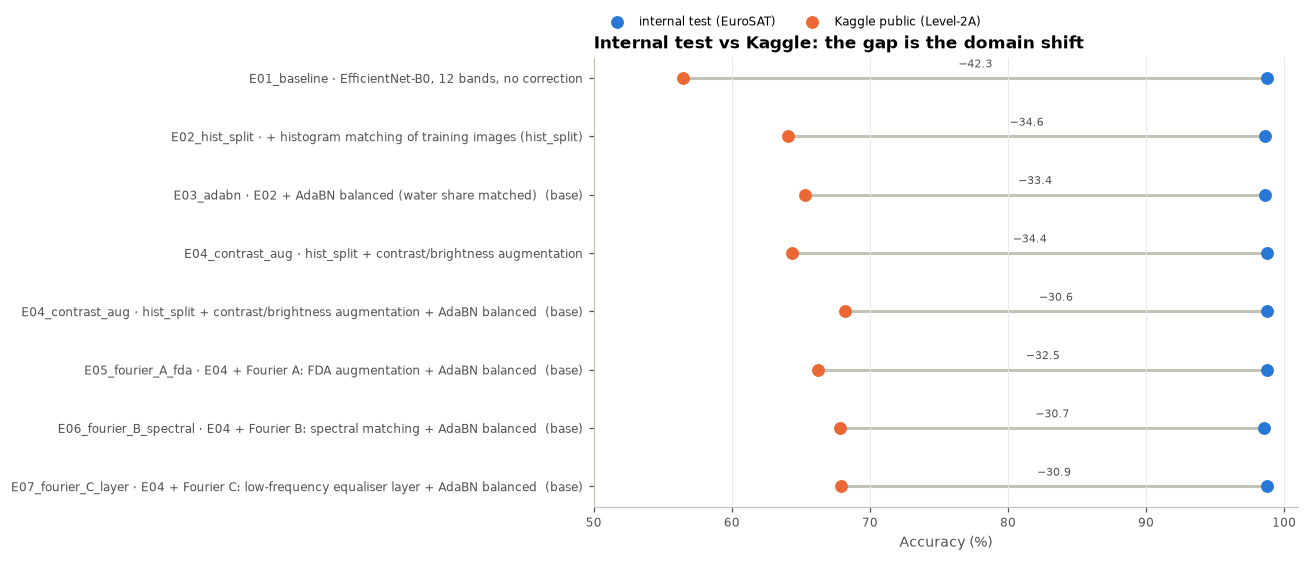

In [4]:
internal = dict(zip(runs["run"], runs["internal test (%)"]))
gap = runs.dropna(subset=["Kaggle public (%)"]).copy()
gap["internal"] = [internal[b] if isinstance(b, str) else v for b, v in zip(gap["base_run"], gap["internal test (%)"])]
gap["label"] = [f"{n} · {d}" + ("  (base)" if isinstance(b, str) else "")
                for n, d, b in zip(gap["notebook"], gap["description"], gap["base_run"])]
gap = gap.reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 0.45 * len(gap) + 1.6))
yy = np.arange(len(gap))[::-1]
ax.hlines(yy, gap["Kaggle public (%)"], gap["internal"], color="#c3c2b7", lw=2, zorder=1)
ax.scatter(gap["internal"], yy, color=TRAIN_COLOR, s=55, zorder=2, label="internal test (EuroSAT)")
ax.scatter(gap["Kaggle public (%)"], yy, color=TEST_COLOR, s=55, zorder=2, label="Kaggle public (Level-2A)")
for yi, k, i in zip(yy, gap["Kaggle public (%)"], gap["internal"]):
    ax.text((k + i) / 2, yi + 0.18, f"−{i - k:.1f}", ha="center", fontsize=7, color="#52514e")
ax.set_yticks(yy, gap["label"], fontsize=8)
ax.set_xlim(50, 101)
ax.set_xlabel("Accuracy (%)")
ax.set_title("Internal test vs Kaggle: the gap is the domain shift", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.04), ncol=2, fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4 · What we learned

1. **The problem is the data shift, not the model.** Every model reaches about 98.8% on EuroSAT but loses
   30–40 points on Kaggle. Bigger models would not help; handling the shift does.
2. **The Kaggle set has about twice as much water** (23.5% vs 9%). Every method that takes statistics from
   the Kaggle images fails if it ignores this: normalising Kaggle images with their own statistics
   (47.82%, tried in `E01_baseline`), plain histogram matching (turns vegetation into "water"),
   AdaBN on all Kaggle images (`E03_adabn`). Matching the water share fixed each of them.
3. **Haze correction by histogram matching is the biggest single step** (+7.6 points, `E02`). After it,
   brightness and colour of training and test images are statistically indistinguishable (`04_haze_correction`).
4. **Contrast within images remains.** Contrast augmentation alone barely helps (+0.3), AdaBN alone
   +1.2, **both together +4.1** over `E02` (`E04`): the contrast-trained model copes much better with
   AdaBN's adjusted statistics.
5. **Not every measurable difference matters.** The detail profile (spectrum) separates training and test
   images almost perfectly (`05_fourier_analysis`), and spectral matching removes it, but the score does
   not change (`E06`). The CNN already ignores it. FDA (`E05`) even hurts.
6. **Label-free measurements** (confidence, view agreement, predicted class mix) predicted the direction of
   most changes, but not their size; only Kaggle settles close calls.
7. **Next lever:** global image statistics are handled; the remaining errors are probably class-specific
   (growing stage, region, season). Learning from the test images themselves (pseudo-labelling) is the next step.